# 02 · Graph construction

Both detectors consume graphs, but the graphs mean very different things:

| | PE graph (host) | NIDS graph (network) |
|---|---|---|
| Node | one static-feature family of the executable (9 nodes) | one network flow (500 nodes) |
| Node features | the family's vector, zero-padded to 512 and L2-normalised | 16 flow statistics, `log1p`-scaled |
| Edges | fixed semantic links between families (same for every file) | flows sharing source IP, src–dst pair, destination port, or adjacent in time |
| Label | file label | window is malicious if > 30% of its flows are attacks |

So the PE graph has **fixed topology and variable features**, while the NIDS graph has **variable topology**: the edges
themselves encode behaviour such as scanning (one source, many ports) or DDoS (many sources, one port).

In [1]:
import sys
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

project_root = Path.cwd().resolve().parent
if str(project_root) not in sys.path:
    sys.path.append(str(project_root))

from src.utils.config import CONFIG

EXP = project_root / CONFIG["experiments_path"]
sns.set_theme(style="whitegrid")
plt.rcParams.update({"font.size": 11, "figure.dpi": 110})
GNN_NAME = "GNN (MFGraph)"


def latest_run(base: Path, filename: str):
    """Most recent timestamped run folder under `base` that contains `filename`."""
    runs = sorted(p.parent for p in base.glob(f"*/{filename}")) if base.exists() else []
    return runs[-1] if runs else None


def missing(path, task):
    print(f"[Missing] {path}\nRun first:  python orchestrator.py -t {task}")

import torch
import networkx as nx
from src.features.pe_extractor import PEFeatureExtractor
from src.graph.feature_graph import FeatureGraphBuilder

/home/simone/miniconda3/envs/thesis-gnn/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/home/simone/miniconda3/envs/thesis-gnn/lib/python3.10/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


## 1. PE graph of a real executable

`putty.exe` (benign) is parsed with `PEFeatureExtractor`, which produces the same 9 families used for EMBER.

In [2]:
extractor, builder = PEFeatureExtractor(), FeatureGraphBuilder()
sample_path = project_root / CONFIG["PEsamples_path"] / "putty.exe"
features = extractor.extract(str(sample_path))
assert features is not None, f"Unable to parse {sample_path}"

graph_data = builder.build(features, label=0)
G = builder.to_networkx(graph_data)
print(f"Nodes: {G.number_of_nodes()} | undirected edges: {G.number_of_edges()} | "
      f"x: {tuple(graph_data.x.shape)} | label: {graph_data.y.item()}")

node_table = pd.DataFrame({
    "family": CONFIG["feature_names"],
    "raw dims": [len(np.atleast_1d(features[n])) for n in CONFIG["feature_names"]],
    "non-zero after padding": (graph_data.x != 0).sum(1).numpy(),
    "degree": [G.degree(i) for i in range(G.number_of_nodes())],
})
display(node_table)

Nodes: 9 | undirected edges: 8 | x: (9, 512) | label: 0


/home/simone/UNI/Master/Tesi/thesis-project/src/graph/feature_graph.py:62: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  node_features.append(torch.tensor(vec, dtype=torch.float32))


,family,raw dims,non-zero after padding,degree
0,general,10,7,3
1,header,10,5,1
2,imported,10,8,1
3,exported,1,0,1
4,section,15,15,1
5,byte_histogram,256,256,1
6,byte_entropy,256,256,1
7,data_directories,32,16,1
8,string,6,6,6


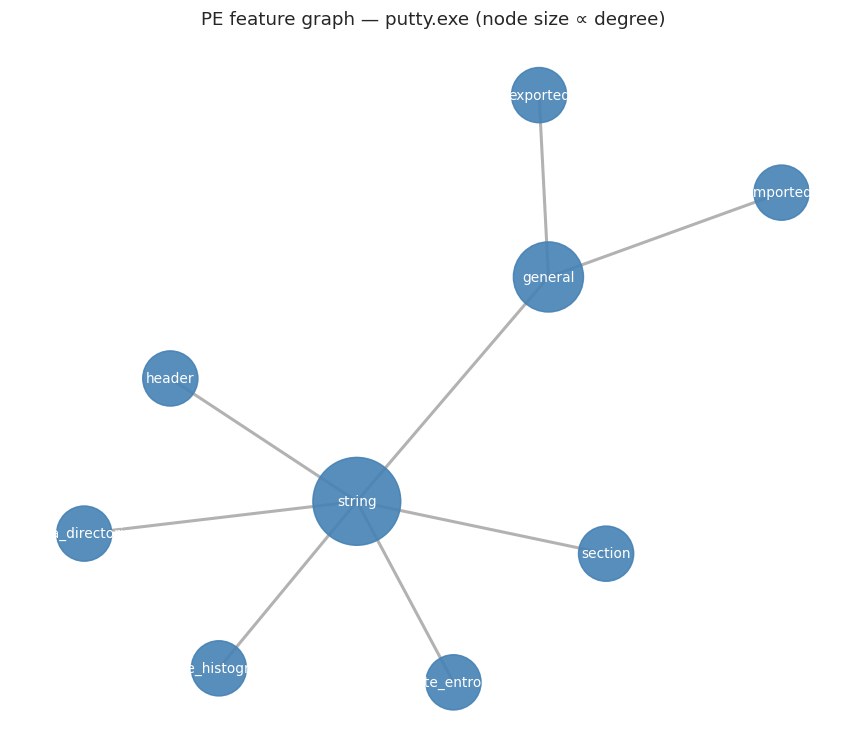

In [3]:
fig, ax = plt.subplots(figsize=(8, 7))
pos = nx.spring_layout(G, seed=32)
deg = np.array([G.degree(n) for n in G.nodes])
nx.draw_networkx_edges(G, pos, width=2, edge_color="gray", alpha=0.6, ax=ax)
nx.draw_networkx_nodes(G, pos, node_size=900 + 400 * deg, node_color="steelblue", alpha=0.9, ax=ax)
nx.draw_networkx_labels(G, pos, nx.get_node_attributes(G, "label"), font_size=9, font_color="white", ax=ax)
ax.set_title("PE feature graph — putty.exe (node size ∝ degree)"); ax.axis("off")
plt.tight_layout()
plt.savefig(EXP / "feature_graph_example.png", dpi=150)
plt.show()

Because the topology is identical for every file, the GNN on PE data learns **how families interact** (e.g. imports
together with section entropy) rather than a structural pattern. The comparison GNN vs. flat baselines in notebook 04 tells
whether that message passing is worth it.

## 2. Benign vs. malware PE graphs from EMBER

Average node-feature profile over the chronological training graphs (January 2018).

[Dataset] Indexing files in /home/simone/UNI/Master/Tesi/thesis-project/data/graphs/ember_graphs/train...


[Dataset] Successfully indexed 61914 graph files.


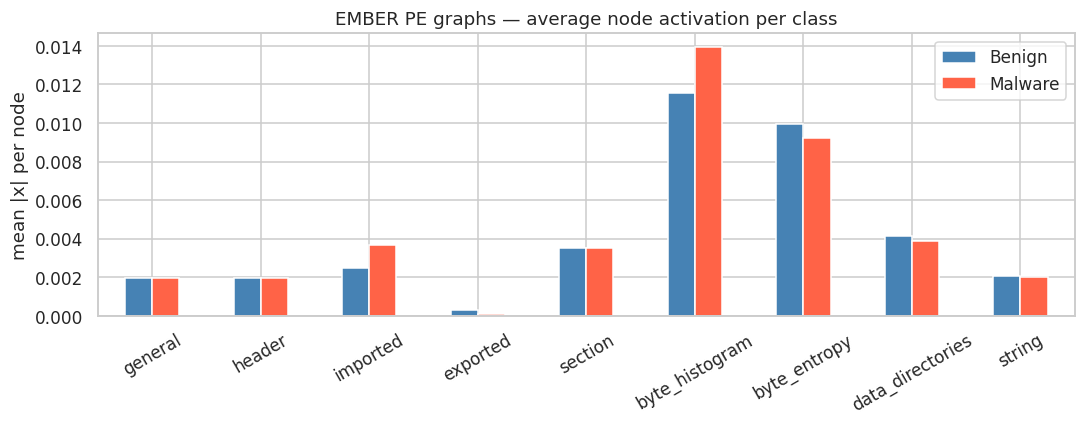

Graphs sampled: 3000 (benign=1378, malware=1622)


In [4]:
from src.training.pe_dataset import PEGraphDataset

pe_train = PEGraphDataset(str(project_root / CONFIG["ember_graphs_path"] / "train"))
rng = np.random.default_rng(CONFIG["random_seed"])
pe_graphs = [pe_train[i] for i in rng.choice(len(pe_train), 3000, replace=False)]
y_pe = np.array([g.y.item() for g in pe_graphs])
# mean absolute activation of each node: how much "signal" each family carries after normalisation
act = np.stack([g.x.abs().mean(1).numpy() for g in pe_graphs])
prof = pd.DataFrame(act, columns=CONFIG["feature_names"]).groupby(y_pe).mean().T
prof.columns = ["Benign", "Malware"]
ax = prof.plot(kind="bar", color=["steelblue", "tomato"], figsize=(10, 4), rot=30)
ax.set_ylabel("mean |x| per node"); ax.set_title("EMBER PE graphs — average node activation per class")
plt.tight_layout(); plt.show()
print(f"Graphs sampled: {len(pe_graphs)} (benign={(y_pe == 0).sum()}, malware={(y_pe == 1).sum()})")

## 3. NIDS graphs: one benign and one malicious window

5651 NIDS graphs


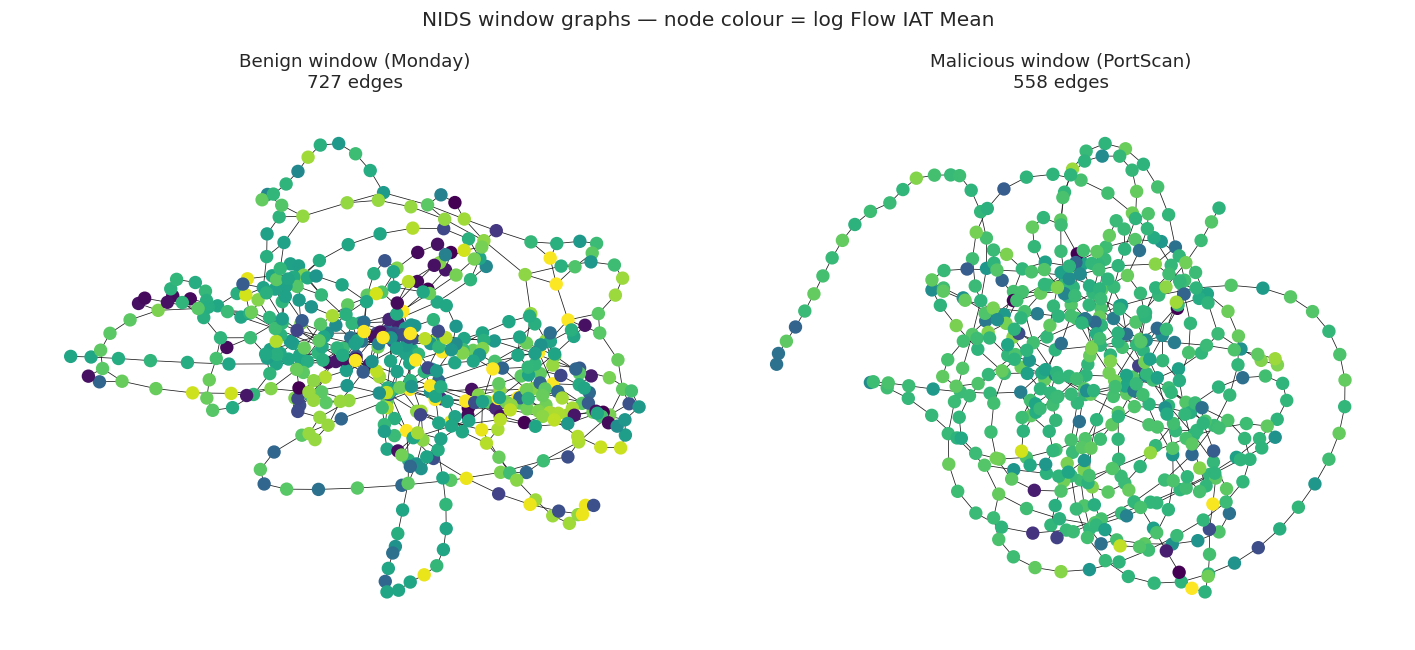

In [5]:
from torch_geometric.utils import to_networkx

NIDS_DIR = project_root / CONFIG["cic_graphs_path"]
files = sorted(NIDS_DIR.glob("*.pt"))
records = []
for f in files:
    g = torch.load(f, weights_only=False)
    records.append({"file": f.name, "scenario": f.name.split("_window_")[0].replace(".pcap_ISCX", ""),
                    "nodes": g.num_nodes, "edges": g.edge_index.size(1) // 2, "label": int(g.y.item())})
nids_meta = pd.DataFrame(records)
print(f"{len(nids_meta)} NIDS graphs")

def show(ax, fname, title):
    g = torch.load(NIDS_DIR / fname, weights_only=False)
    Gn = to_networkx(g, to_undirected=True)
    nx.draw(Gn, pos=nx.spring_layout(Gn, seed=1), ax=ax, node_size=60, width=0.5,
            node_color=g.x[:, 4].numpy(), cmap="viridis")  # colour = log Flow IAT Mean
    ax.set_title(f"{title}\n{Gn.number_of_edges()} edges")

fig, axes = plt.subplots(1, 2, figsize=(13, 6))
show(axes[0], nids_meta.query("label == 0 and scenario.str.startswith('Monday')").file.iloc[10], "Benign window (Monday)")
show(axes[1], nids_meta.query("label == 1 and scenario.str.contains('PortScan')").file.iloc[10], "Malicious window (PortScan)")
plt.suptitle("NIDS window graphs — node colour = log Flow IAT Mean"); plt.tight_layout(); plt.show()

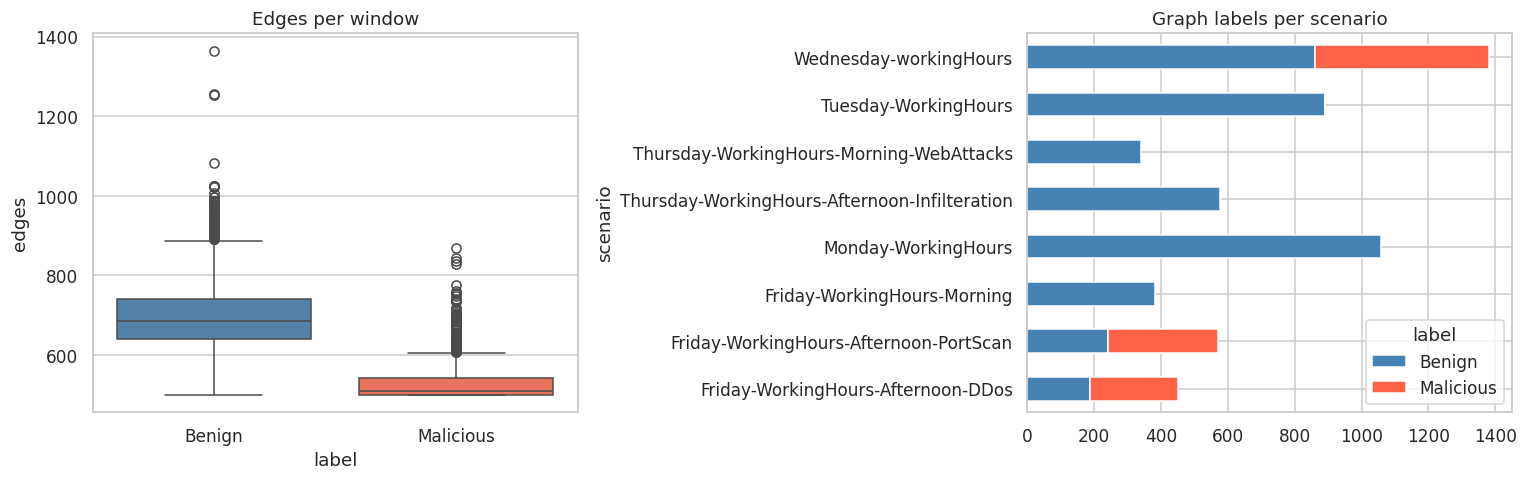

edges                                                 
        count   mean   std    min    25%    50%    75%     max
label                                                         
0      4536.0  692.5  83.3  499.0  640.0  686.0  740.0  1365.0
1      1115.0  532.5  52.5  499.0  499.0  510.0  542.0   870.0

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sns.boxplot(data=nids_meta, x="label", y="edges", hue="label", ax=axes[0], palette=["steelblue", "tomato"], legend=False)
axes[0].set_xticks([0, 1], ["Benign", "Malicious"]); axes[0].set_title("Edges per window")
pd.crosstab(nids_meta.scenario, nids_meta.label).rename(columns={0: "Benign", 1: "Malicious"}).plot(
    kind="barh", stacked=True, ax=axes[1], color=["steelblue", "tomato"])
axes[1].set_title("Graph labels per scenario")
plt.tight_layout(); plt.show()
display(nids_meta.groupby("label")[["edges"]].describe().round(1))

**Takeaways**
* Malicious windows are **sparser and more uniform** (median ~510 edges vs ~690 for benign, much smaller spread): attack
  traffic repeats the same few source/port patterns, while benign windows mix many hosts and services. Topology alone is
  therefore informative — information the flat baselines cannot see.
* The PE graph is a small tree (9 nodes, 8 edges) with `string` and `general` as hubs, so message passing mostly flows through these two families.
* Graph labels are imbalanced and concentrated in the attack-heavy afternoons. The temporal split per scenario
  (notebook 01-CIC) keeps both classes in the test set.